# Telecom Customer Churn Analysis
**Author:** Piyush | **Tools:** Python (pandas, seaborn, scikit-learn), Power BI

## 1. Business problem
A telecom company in California is losing customers every quarter. Acquiring a new customer costs far more than keeping one, so leadership wants to know:
1. How many customers are we losing, and what does it cost us?
2. **Who** is leaving (segments), **when** (tenure) and **why** (reasons)?
3. Can we **predict** who will leave next, so retention teams can act early?
4. What should we **do** about it?

**Data:** 3 files - customer churn (7,043 customers, Q2 2022), data dictionary, zip code population.

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import warnings, os; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns', 60)
os.makedirs('../images', exist_ok=True); os.makedirs('../data/processed', exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(f'../images/{name}.png', dpi=130); plt.show()

## 2. Load the data

In [4]:
churn = pd.read_csv('../data/raw/telecom_customer_churn.csv')
pop   = pd.read_csv('../data/raw/telecom_zipcode_population.csv')
dic   = pd.read_csv('../data/raw/telecom_data_dictionary.csv', encoding='latin1')
print('Customers:', churn.shape, '| Zip population:', pop.shape, '| Dictionary:', dic.shape)
churn.head()

Customers: (7043, 38) | Zip population: (1671, 2) | Dictionary: (40, 3)


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,9,NaN,Yes,42.39,No,Yes,Cable,16.0,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,9,NaN,Yes,10.69,Yes,Yes,Cable,10.0,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,4,Offer E,Yes,33.65,No,Yes,Fiber Optic,30.0,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,13,Offer D,Yes,27.82,No,Yes,Fiber Optic,4.0,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,3,NaN,Yes,7.38,No,Yes,Fiber Optic,11.0,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [3]:
churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

In [5]:
# Data dictionary - what each column means
dic[dic['Table']=='Customer Churn'][['Field','Description']].style.set_properties(**{'text-align':'left'})

,Field,Description
0,CustomerID,A unique ID that identifies each customer
1,Gender,"The customers gender: Male, Female"
2,Age,"The customers current age, in years, at the time the fiscal quarter ended (Q2 2022)"
3,Married,"Indicates if the customer is married: Yes, No"
4,Number of Dependents,"Indicates the number of dependents that live with the customer (dependents could be children, parents, grandparents, etc.)"
5,City,The city of the customers primary residence in California
6,Zip Code,The zip code of the customers primary residence
7,Latitude,The latitude of the customers primary residence
8,Longitude,The longitude of the customers primary residence
9,Number of Referrals,Indicates the number of times the customer has referred a friend or family member to this company to date


**What I found:** 7,043 rows and 38 columns, one row per customer. The target is `Customer Status` (Stayed / Churned / Joined). `Churn Category` and `Churn Reason` are only filled for churned customers, so they explain *why* people left but must **not** be used to predict churn (data leakage).

## 3. Merge the zip code population

In [5]:
df = churn.merge(pop, on='Zip Code', how='left')
assert len(df) == len(churn), 'merge changed row count'
print('Rows before/after merge:', len(churn), len(df), '| missing population:', df['Population'].isna().sum())

Rows before/after merge: 7043 7043 | missing population: 0


## 4. Data quality checks

In [6]:
print('Duplicate customer IDs:', df['Customer ID'].duplicated().sum())
miss = df.isna().sum(); miss = miss[miss>0].to_frame('missing'); miss['%'] = (miss['missing']/len(df)*100).round(1); miss

Duplicate customer IDs: 0


,missing,%
Offer,3877,55.0
Avg Monthly Long Distance Charges,682,9.7
Multiple Lines,682,9.7
Internet Type,1526,21.7
Avg Monthly GB Download,1526,21.7
Online Security,1526,21.7
Online Backup,1526,21.7
Device Protection Plan,1526,21.7
Premium Tech Support,1526,21.7
Streaming TV,1526,21.7


In [7]:
print('Negative Monthly Charge rows:', (df['Monthly Charge']<0).sum())
df[['Age','Tenure in Months','Monthly Charge','Total Charges','Total Revenue']].describe().T

Negative Monthly Charge rows: 120


,count,mean,std,min,25%,50%,75%,max
Age,7043.0,46.509726,16.750352,19.00,32.00,46.00,60.000,80.00
Tenure in Months,7043.0,32.386767,24.542061,1.00,9.00,29.00,55.000,72.00
Monthly Charge,7043.0,63.596131,31.204743,-10.00,30.40,70.05,89.750,118.75
Total Charges,7043.0,2280.381264,2266.220462,18.80,400.15,1394.55,3786.600,8684.80
Total Revenue,7043.0,3034.379056,2865.204542,21.36,605.61,2108.64,4801.145,11979.34


**What I found:** No duplicates. The missing values are **structural, not errors**: customers with no internet service have blank internet-related fields (1,526), customers with no phone service have blank phone fields (682), and customers who accepted no offer have a blank `Offer` (3,877). Churn fields are blank for people who did not churn (5,174). One real quality issue: **120 customers have a negative `Monthly Charge`** (likely credits) - I flag them and keep them.

## 5. Data cleaning

In [8]:
df['Offer'] = df['Offer'].fillna('No Offer')
df['Internet Type'] = df['Internet Type'].fillna('No Internet')
no_service_cols = ['Multiple Lines','Online Security','Online Backup','Device Protection Plan',
                   'Premium Tech Support','Streaming TV','Streaming Movies','Streaming Music','Unlimited Data']
df[no_service_cols] = df[no_service_cols].fillna('No')
df[['Avg Monthly GB Download','Avg Monthly Long Distance Charges']] = df[['Avg Monthly GB Download','Avg Monthly Long Distance Charges']].fillna(0)
df['Negative Charge Flag'] = (df['Monthly Charge'] < 0).astype(int)
df['Churn Flag'] = (df['Customer Status'] == 'Churned').astype(int)
print('Remaining nulls outside churn fields:', df.drop(columns=['Churn Category','Churn Reason']).isna().sum().sum())
df['Customer Status'].value_counts()

Remaining nulls outside churn fields: 0


Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [9]:
# 'Joined' customers are new this quarter and haven't had a chance to churn -> exclude from churn-rate analysis
base   = df[df['Customer Status']!='Joined'].copy()     # Stayed + Churned
active = df[df['Customer Status']!='Churned'].copy()    # current customers (to score later)
print('Analysis base:', len(base), '| Overall churn rate: %.1f%%' % (base['Churn Flag'].mean()*100))

Analysis base: 6589 | Overall churn rate: 28.4%


**Decision:** analysis base = 6,589 customers (Stayed + Churned). Overall churn rate = **28.4%**. Blanks were filled with meaningful labels ("No Internet", "No Offer", "No") instead of dropping rows, so no customers were lost.

## 6. Feature engineering

In [10]:
df['Tenure Band'] = pd.cut(df['Tenure in Months'], [0,6,12,24,48,72], labels=['0-6','7-12','13-24','25-48','49-72'])
df['Age Band'] = pd.cut(df['Age'], [0,29,39,49,64,100], labels=['<30','30-39','40-49','50-64','65+'])
addons = ['Online Security','Online Backup','Device Protection Plan','Premium Tech Support']
df['Num Addons'] = (df[addons]=='Yes').sum(axis=1)
base = df[df['Customer Status']!='Joined'].copy(); active = df[df['Customer Status']!='Churned'].copy()
base[['Tenure in Months','Tenure Band','Age','Age Band','Num Addons']].head()

,Tenure in Months,Tenure Band,Age,Age Band,Num Addons
0,9,7-12,37,30-39,2
1,9,7-12,46,40-49,0
2,4,0-6,50,50-64,1
3,13,13-24,78,65+,2
4,3,0-6,75,65+,1


## 7. Univariate EDA - understanding each variable

NameError: name 'df' is not defined

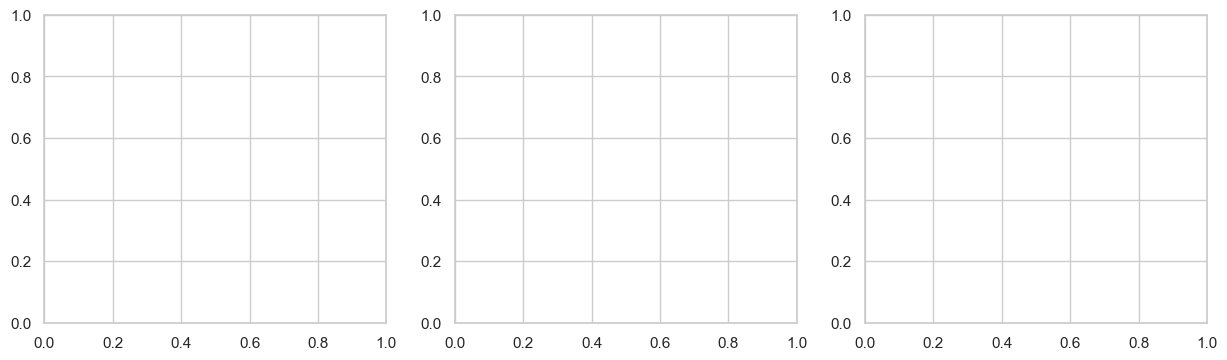

In [6]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
df['Customer Status'].value_counts().plot.bar(ax=ax[0], color=['#4472c4','#c0504d','#70ad47']); ax[0].set_title('Customer status')
sns.histplot(df['Tenure in Months'], bins=30, ax=ax[1], color='#4472c4'); ax[1].set_title('Tenure (months)')
sns.histplot(df['Monthly Charge'], bins=30, ax=ax[2], color='#4472c4'); ax[2].set_title('Monthly charge')
save('01_univariate')

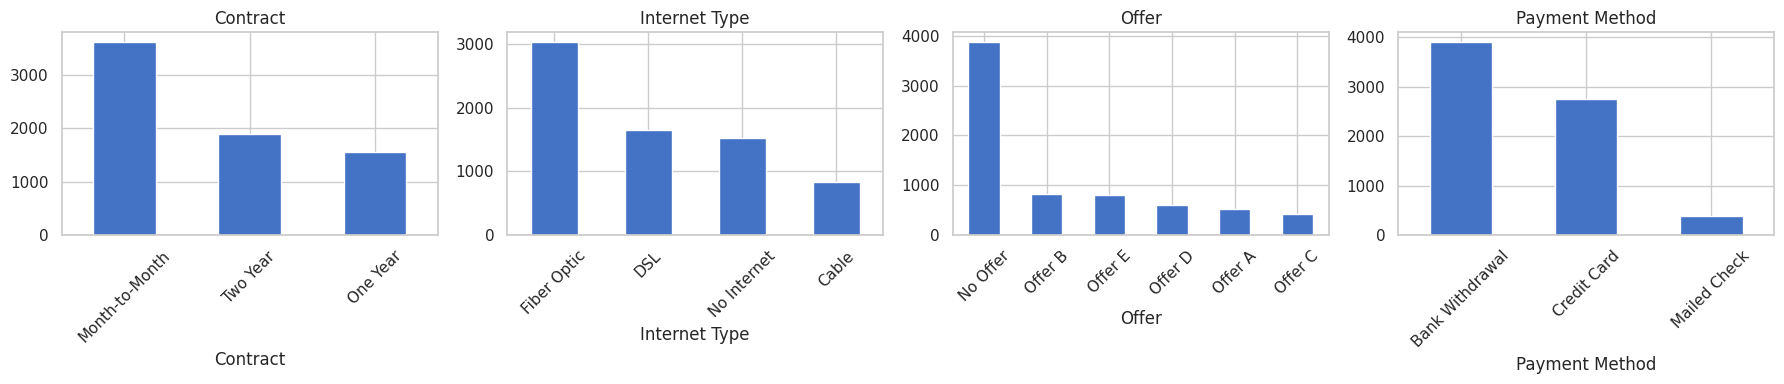

In [12]:
fig, ax = plt.subplots(1,4, figsize=(18,4))
for a, col in zip(ax, ['Contract','Internet Type','Offer','Payment Method']):
    df[col].value_counts().plot.bar(ax=a, color='#4472c4'); a.set_title(col); a.tick_params(axis='x', rotation=45)
save('02_categoricals')

**What I found:** 67% of customers stayed, 26.5% churned and 6.4% joined. Tenure has two humps - lots of brand-new customers and a large loyal group at ~70 months. Over half of customers are on month-to-month contracts, and Fiber Optic is the most common internet type.

## 8. Bivariate EDA - churn rate vs every driver

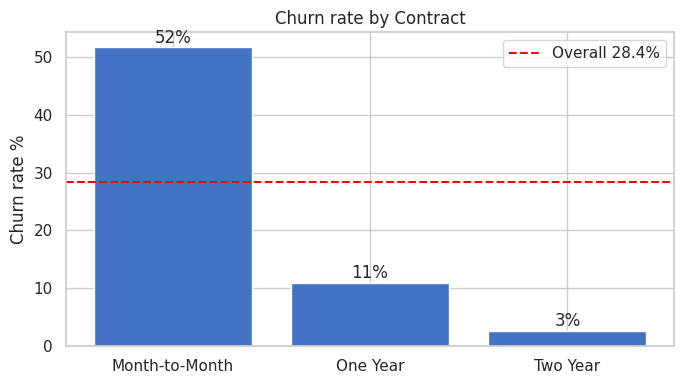

,mean,sum,count
Contract,,,
Month-to-Month,0.517,1655,3202
One Year,0.109,166,1526
Two Year,0.026,48,1861


In [13]:
def churn_by(col, title=None, order=None, figsize=(7,4)):
    g = base.groupby(col, observed=True)['Churn Flag'].agg(['mean','sum','count'])
    if order: g = g.reindex(order)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(g.index.astype(str), g['mean']*100, color='#4472c4')
    ax.axhline(base['Churn Flag'].mean()*100, color='red', ls='--', label='Overall 28.4%')
    for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.8, f'{b.get_height():.0f}%', ha='center')
    ax.set_ylabel('Churn rate %'); ax.set_title(title or f'Churn rate by {col}'); ax.legend()
    save('bi_'+col.lower().replace(' ','_')); return g.round(3)
churn_by('Contract', order=['Month-to-Month','One Year','Two Year'])

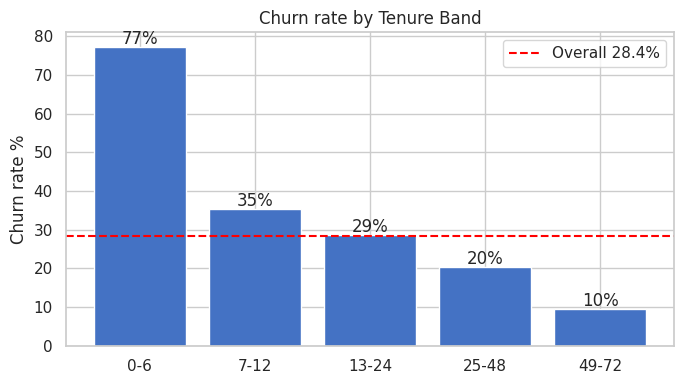

,mean,sum,count
Tenure Band,,,
0-6,0.772,784,1016
7-12,0.353,253,716
13-24,0.287,294,1024
25-48,0.204,325,1594
49-72,0.095,213,2239


In [14]:
churn_by('Tenure Band')

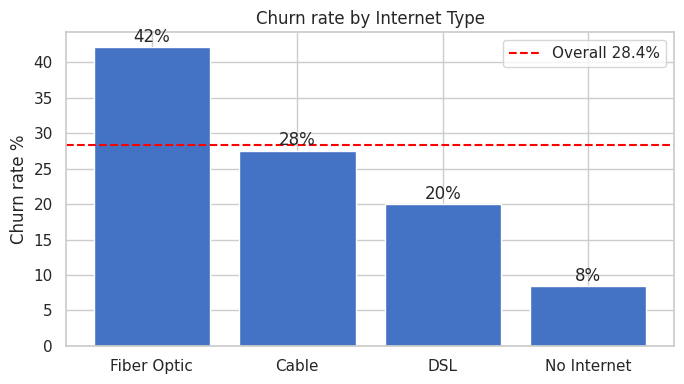

,mean,sum,count
Internet Type,,,
Fiber Optic,0.421,1236,2934
Cable,0.275,213,774
DSL,0.200,307,1537
No Internet,0.084,113,1344


In [15]:
churn_by('Internet Type', order=['Fiber Optic','Cable','DSL','No Internet'])

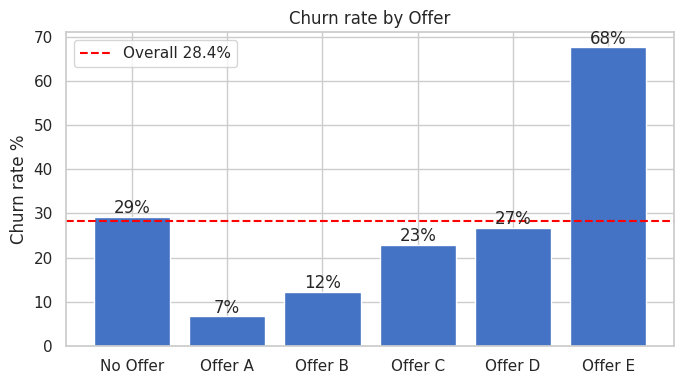

,mean,sum,count
Offer,,,
No Offer,0.292,1051,3598
Offer A,0.067,35,520
Offer B,0.123,101,824
Offer C,0.229,95,415
Offer D,0.267,161,602
Offer E,0.676,426,630


In [16]:
churn_by('Offer', order=['No Offer','Offer A','Offer B','Offer C','Offer D','Offer E'])

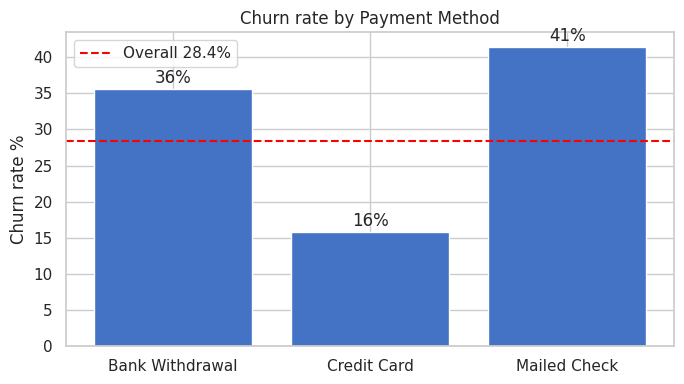

,mean,sum,count
Payment Method,,,
Bank Withdrawal,0.356,1329,3728
Credit Card,0.158,398,2518
Mailed Check,0.414,142,343


In [17]:
churn_by('Payment Method')

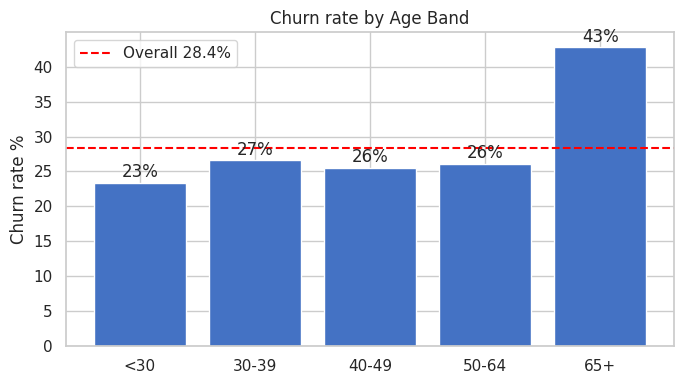

,mean,sum,count
Age Band,,,
<30,0.233,304,1302
30-39,0.266,309,1162
40-49,0.255,318,1245
50-64,0.261,462,1768
65+,0.428,476,1112


In [18]:
churn_by('Age Band')

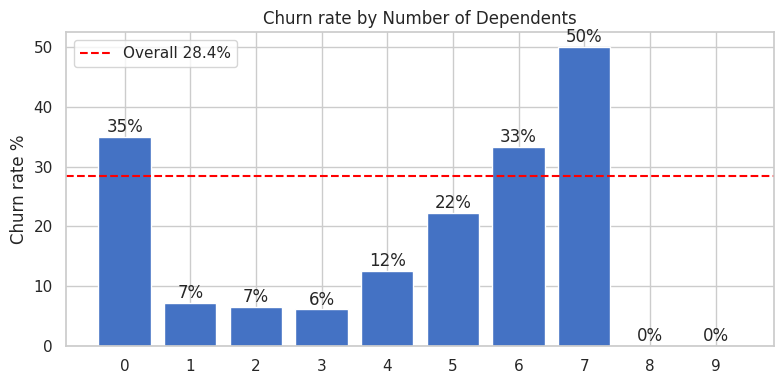

,mean,sum,count
Number of Dependents,,,
0,0.350,1763,5042
1,0.072,38,526
2,0.065,33,506
3,0.061,30,491
4,0.125,1,8


In [19]:
churn_by('Number of Dependents', figsize=(8,4)).head(5)

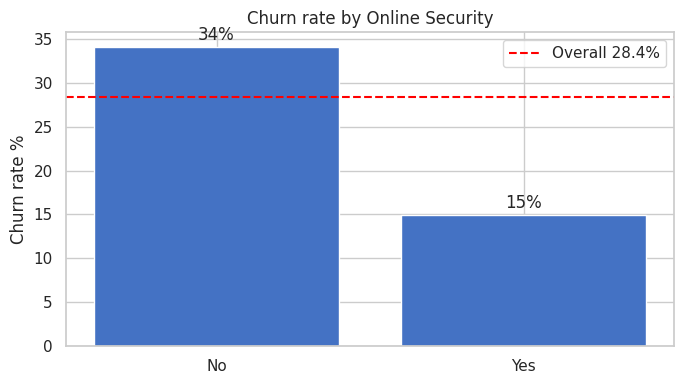

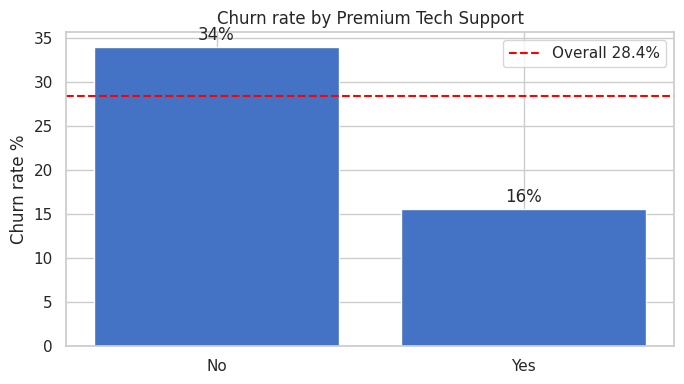

(                  mean   sum  count
 Online Security                    
 No               0.341  1574   4616
 Yes              0.150   295   1973,
                        mean   sum  count
 Premium Tech Support                    
 No                    0.340  1559   4592
 Yes                   0.155   310   1997)

In [20]:
churn_by('Online Security'), churn_by('Premium Tech Support')

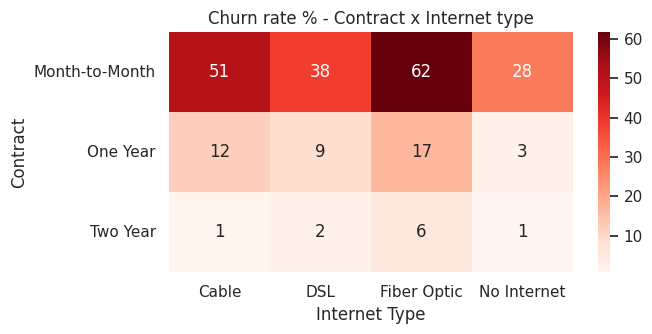

In [21]:
# Contract x Internet type: where is the risk concentrated?
pt = base.pivot_table(index='Contract', columns='Internet Type', values='Churn Flag', aggfunc='mean')*100
plt.figure(figsize=(7,3.5)); sns.heatmap(pt, annot=True, fmt='.0f', cmap='Reds'); plt.title('Churn rate % - Contract x Internet type'); save('heatmap_contract_internet')

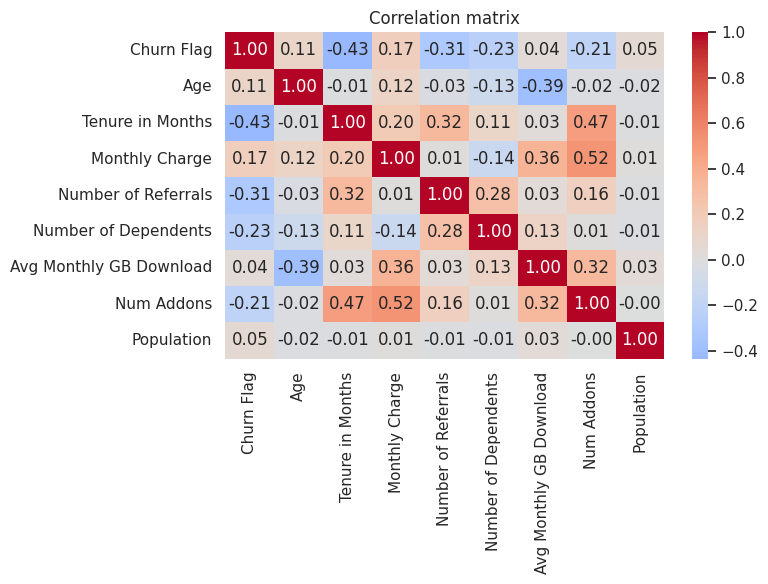

In [22]:
num = base[['Churn Flag','Age','Tenure in Months','Monthly Charge','Number of Referrals','Number of Dependents','Avg Monthly GB Download','Num Addons','Population']]
plt.figure(figsize=(8,6)); sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Correlation matrix'); save('correlation')

**What I found**
- **Contract:** month-to-month 52% churn vs one-year 11% and two-year 3%. Month-to-month customers are **89% of all churners**.
- **Tenure:** 77% churn in the first 6 months, falling to under 10% after 4 years. The first year is the danger zone.
- **Internet type:** Fiber Optic 42% vs DSL 20%, and fiber customers pay ~$90/month (highest revenue segment). Fiber + month-to-month is the worst combination (62%).
- **Offer:** Offer E customers churn at **68%**; Offers A and B retain well (7%, 12%).
- **Payment:** bank withdrawal 36% and mailed check 41% vs credit card 16%.
- **Age:** customers 65+ churn at 43%, others sit around 23-27%.
- **Add-ons:** customers without Online Security or Tech Support churn at ~45% vs ~15% with them.
- **Dependents:** no dependents 35% vs ~7% for customers with dependents.
- Correlation shows tenure is the strongest negative correlate of churn.

## 9. Why do customers leave? (churn reasons)

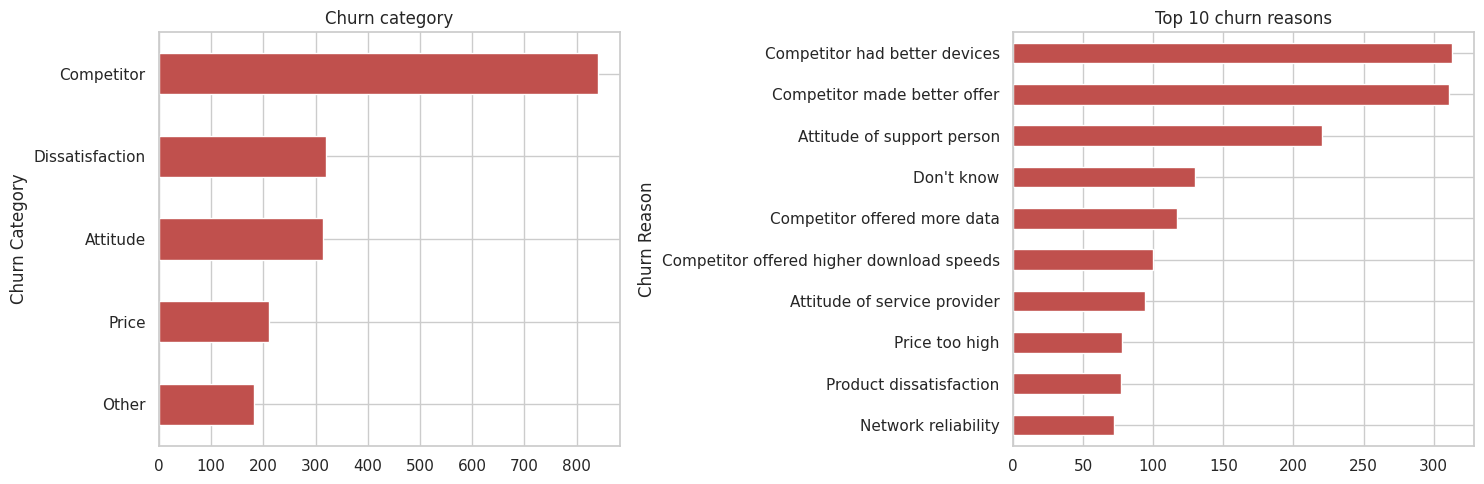

Churn Category
Competitor         45.0
Dissatisfaction    17.2
Attitude           16.8
Price              11.3
Other               9.7
Name: proportion, dtype: float64

In [23]:
ch = base[base['Churn Flag']==1]
fig, ax = plt.subplots(1,2, figsize=(15,5))
ch['Churn Category'].value_counts().sort_values().plot.barh(ax=ax[0], color='#c0504d'); ax[0].set_title('Churn category')
ch['Churn Reason'].value_counts().head(10).sort_values().plot.barh(ax=ax[1], color='#c0504d'); ax[1].set_title('Top 10 churn reasons')
save('reasons')
(ch['Churn Category'].value_counts(normalize=True)*100).round(1)

In [24]:
# San Diego deep-dive
city = base.groupby('City')['Churn Flag'].agg(churn_rate='mean', churned='sum', customers='count')
display(city[city.customers>=30].sort_values('churn_rate', ascending=False).head(8).round(3))
sd = base[base.City=='San Diego']; rest = base[base.City!='San Diego']
print('San Diego churn: %.1f%% | rest of California: %.1f%%' % (sd['Churn Flag'].mean()*100, rest['Churn Flag'].mean()*100))
print('San Diego churners citing competitor: %.0f%%' % (sd[sd['Churn Flag']==1]['Churn Category'].eq('Competitor').mean()*100))
sd[sd['Churn Flag']==1]['Churn Reason'].value_counts().head(3)

,churn_rate,churned,customers
City,,,
San Diego,0.665,185,278
Fallbrook,0.634,26,41
Temecula,0.611,22,36
Glendale,0.382,13,34
Escondido,0.333,16,48
San Francisco,0.320,31,97
Pasadena,0.300,9,30
Stockton,0.293,12,41


San Diego churn: 66.5% | rest of California: 26.7%
San Diego churners citing competitor: 82%


Churn Reason
Competitor made better offer    146
Don't know                       15
Attitude of support person        8
Name: count, dtype: int64

**What I found:** Competitors drive **45%** of churn (better devices 313, better offers 311, more data 117, faster speeds 100). Support attitude is next (17%), and price is only 11%. **San Diego is an outlier:** 66% churn vs ~27% elsewhere, with 82% of leavers citing a competitor, mainly "competitor made better offer". That looks like a local competitive campaign.

## 10. Business impact

In [7]:
lost_customers = len(ch); lost_monthly = ch['Monthly Charge'].sum(); lost_total = ch['Total Revenue'].sum()
early = (ch['Tenure in Months']<=12).mean()*100
print(f'Customers lost: {lost_customers:,}')
print(f'Monthly revenue lost: ${lost_monthly:,.0f}  (annualised ~${lost_monthly*12:,.0f})')
print(f'Lifetime revenue from churned customers: ${lost_total:,.0f}')
print(f'Churners who left within 12 months: {early:.0f}%')
print(f"Avg tenure - churned: {ch['Tenure in Months'].mean():.1f} months vs stayed: {base[base['Churn Flag']==0]['Tenure in Months'].mean():.1f} months")

NameError: name 'ch' is not defined

## 11. Predictive model (simple Random Forest)
Goal: predict which customers are likely to churn. I drop IDs, location text, and the churn reason fields (they only exist *after* a customer leaves, which would be data leakage).

In [26]:
drop = ['Customer ID','Customer Status','Churn Category','Churn Reason','Churn Flag','City','Zip Code','Latitude','Longitude',
        'Tenure Band','Age Band','Total Charges','Total Revenue','Gender']
X = pd.get_dummies(base.drop(columns=drop), drop_first=True)   # text categories -> 0/1 columns
y = base['Churn Flag']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('Train:', Xtr.shape, '| Test:', Xte.shape)

Train: (4941, 38) | Test: (1648, 38)


In [27]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=42)
rf.fit(Xtr, ytr)
prob = rf.predict_proba(Xte)[:, 1]
print('ROC-AUC:', round(roc_auc_score(yte, prob), 3))
pred = (prob >= 0.5).astype(int)
print(classification_report(yte, pred, target_names=['Stayed','Churned']))
print(confusion_matrix(yte, pred))

ROC-AUC: 0.925
              precision    recall  f1-score   support

      Stayed       0.90      0.88      0.89      1181
     Churned       0.72      0.76      0.74       467

    accuracy                           0.85      1648
   macro avg       0.81      0.82      0.82      1648
weighted avg       0.85      0.85      0.85      1648

[[1043  138]
 [ 111  356]]


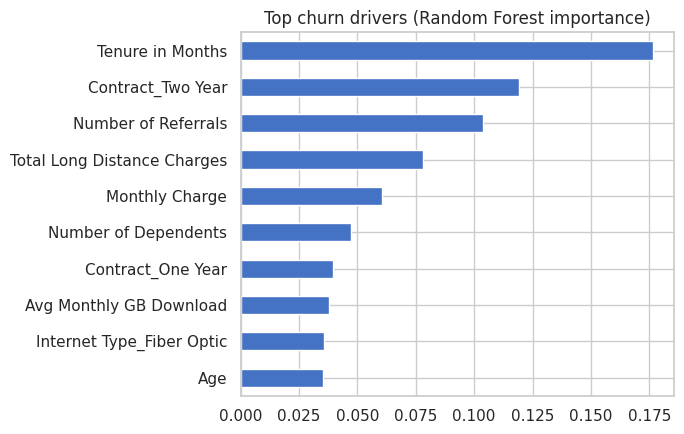

Tenure in Months               0.177
Contract_Two Year              0.119
Number of Referrals            0.104
Total Long Distance Charges    0.078
Monthly Charge                 0.061
Number of Dependents           0.047
Contract_One Year              0.039
Avg Monthly GB Download        0.038
dtype: float64

In [28]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10)[::-1].plot.barh(figsize=(7,4.5), color='#4472c4'); plt.title('Top churn drivers (Random Forest importance)'); save('importance')
imp.head(8).round(3)

**What I found:** The Random Forest separates churners from stayers well (ROC-AUC about 0.93). The top predictors are **tenure, contract type, number of referrals, monthly charge and dependents** - the same story the EDA told, which gives me confidence in the findings.

## 12. Score current customers (who is at risk now?)

In [29]:
rf.fit(X, y)   # retrain on all labelled customers
Xa = pd.get_dummies(active.drop(columns=drop), drop_first=True).reindex(columns=X.columns, fill_value=0)
active['Churn Risk'] = rf.predict_proba(Xa)[:, 1]
active['Risk Tier'] = pd.cut(active['Churn Risk'], [-.01,.3,.6,1.0], labels=['Low','Medium','High'])
print(active['Risk Tier'].value_counts())
hi = active[active['Risk Tier']=='High']
print(f"High-risk customers: {len(hi)} | monthly revenue at risk: ${hi['Monthly Charge'].sum():,.0f}")
active.sort_values('Churn Risk', ascending=False)[['Customer ID','City','Contract','Internet Type','Offer','Tenure in Months','Monthly Charge','Churn Risk','Risk Tier']].head(10).round(3)

Risk Tier
Low       3842
Medium     784
High       548
Name: count, dtype: int64
High-risk customers: 548 | monthly revenue at risk: $28,682


,Customer ID,City,Contract,Internet Type,Offer,Tenure in Months,Monthly Charge,Churn Risk,Risk Tier
6765,9605-WGJVW,Stockton,Month-to-Month,Fiber Optic,No Offer,1,70.20,0.996,High
5706,8040-MNRTF,Taft,Month-to-Month,Fiber Optic,No Offer,1,71.10,0.996,High
3124,4482-EWFMI,Arcadia,Month-to-Month,Fiber Optic,No Offer,2,69.70,0.995,High
5287,7465-ZZRVX,Ceres,Month-to-Month,Fiber Optic,No Offer,1,70.35,0.995,High
2302,3295-YVUSR,Glendale,Month-to-Month,Fiber Optic,No Offer,2,72.60,0.995,High
5367,7577-SWIFR,Glendale,Month-to-Month,Fiber Optic,No Offer,1,89.25,0.995,High
1004,1452-VOQCH,Hinkley,Month-to-Month,Fiber Optic,No Offer,1,75.10,0.993,High
6323,8950-MTZNV,Carson,Month-to-Month,DSL,Offer E,1,44.95,0.992,High
4360,6145-NNPNO,Santa Rosa,Month-to-Month,Cable,Offer E,1,44.15,0.992,High
2320,3318-NMQXL,El Monte,Month-to-Month,Fiber Optic,Offer E,3,92.00,0.992,High


## 13. Recommendations
| # | Action | Evidence |
|---|---|---|
| 1 | Convert month-to-month customers to 1-2 year contracts (discount or device incentive), starting with first-year customers | 52% vs 3-11% churn; 89% of churners are month-to-month |
| 2 | Build a 6-month onboarding / check-in programme | 77% churn in first 6 months |
| 3 | Retire or redesign Offer E, model new offers on A and B | Offer E 68% churn vs 7-12% for A/B |
| 4 | Competitive response in San Diego (matching offers, device upgrades) | 66% churn, 82% cite competitor |
| 5 | Bundle Online Security and Tech Support free for a trial period, especially on fiber | ~45% churn without vs ~15% with |
| 6 | Support staff training and a proactive retention call list from the model's High-risk tier | Support attitude = 17% of churn; 548 high-risk customers |
| 7 | Encourage credit card / autopay over bank withdrawal and mailed check | 16% vs 36-41% churn |

## 14. Export for the dashboard

In [8]:
keep = ['Customer ID','Gender','Age','Age Band','Married','Number of Dependents','City','Zip Code','Latitude','Longitude','Population',
        'Number of Referrals','Tenure in Months','Tenure Band','Offer','Contract','Internet Type','Payment Method','Paperless Billing',
        'Online Security','Premium Tech Support','Num Addons','Monthly Charge','Total Revenue','Customer Status','Churn Flag','Churn Category','Churn Reason']
out = df[keep].copy()
out['Tenure Band Sort'] = out['Tenure Band'].map({'0-6':1,'7-12':2,'13-24':3,'24-48':4,'25-48':4,'49-72':5})
out['Age Band Sort'] = out['Age Band'].map({'<30':1,'30-39':2,'40-49':3,'50-64':4,'65+':5})
out = out.merge(active[['Customer ID','Churn Risk','Risk Tier']], on='Customer ID', how='left')
out.to_csv('../data/processed/churn_clean.csv', index=False)
print(out.shape); out.head(3)

NameError: name 'df' is not defined